<a href="https://colab.research.google.com/github/nourkhoulani3-dot/Kidney-Disease-Diagnosis/blob/main/notebooks/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Load the new dataset
df = pd.read_csv("/content/BD-KDD Dataset.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (988, 26)


,Sl. No.,Age,Bp,Sg,Al,Su,Rbc,Pc,Pcc,Ba,...,Pcv,Wbcc,Rbcc,Htn,Dm,Cad,Appet,Pe,Ane,Class
0,1,58,147,1.025,1,3,0,1,0,0,...,43,12342,4.3,1,0,0,1,1,0,0
1,2,71,142,1.025,2,3,1,0,1,0,...,47,7249,3.7,0,1,1,0,1,1,1
2,3,48,179,1.005,0,4,1,1,0,1,...,37,4111,3.7,0,0,0,0,0,1,0
3,4,34,70,1.005,1,3,1,1,0,0,...,44,4682,4.0,1,0,1,1,0,1,1
4,5,62,120,1.020,4,0,1,0,1,0,...,54,5161,4.7,0,0,1,0,1,0,1


In [2]:
# X contains the patient measurements.
# Remove the record number and the diagnosis.
X = df.drop(columns=["Sl. No.", "Class"])

# y contains the diagnosis: 0 = healthy, 1 = kidney disease
y = df["Class"]

print("Patient measurements:", X.shape)
print("\nDiagnosis counts:")
print(y.value_counts())

Patient measurements: (988, 24)

Diagnosis counts:
Class
1    507
0    481
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 790
Testing records: 198


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Scale the measurements, then train Logistic Regression
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Model is ready!")

Model is ready!


In [5]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    error_score="raise"
)

results = pd.DataFrame({
    "Metric": ["accuracy", "precision", "recall", "f1", "roc_auc"],
    "Mean": [
        scores[f"test_{metric}"].mean()
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]
    ],
    "Standard deviation": [
        scores[f"test_{metric}"].std()
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]
    ]
})

results.round(3)

,Metric,Mean,Standard deviation
0,accuracy,0.490,0.047
1,precision,0.502,0.041
2,recall,0.553,0.049
3,f1,0.526,0.045
4,roc_auc,0.474,0.030


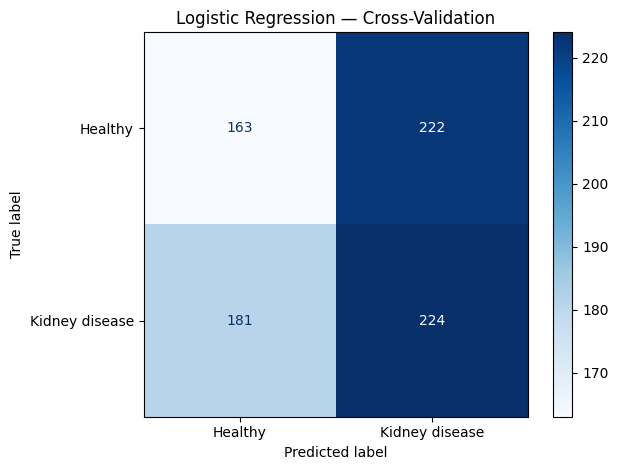

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get a validation prediction for each training record
cv_predictions = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv
)

ConfusionMatrixDisplay.from_predictions(
    y_train,
    cv_predictions,
    labels=[0, 1],
    display_labels=["Healthy", "Kidney disease"],
    cmap="Blues"
)

plt.title("Logistic Regression — Cross-Validation")
plt.tight_layout()
plt.show()

In [7]:
# Fit the model using only the training records
model.fit(X_train, y_train)

# Get the coefficient for each measurement
coefficients = model.named_steps["classifier"].coef_[0]

feature_effects = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients
})

# Display the 10 largest coefficients by magnitude
feature_effects["Magnitude"] = feature_effects["Coefficient"].abs()

top_features = feature_effects.nlargest(10, "Magnitude")
top_features[["Feature", "Coefficient"]]

,Feature,Coefficient
1,Bp,-0.217783
10,Bu,0.093838
8,Ba,-0.088120
4,Su,-0.078886
15,Pcv,-0.063663
21,Appet,-0.063489
23,Ane,0.062681
9,Bgr,0.060126
19,Dm,0.059640
7,Pcc,-0.058803


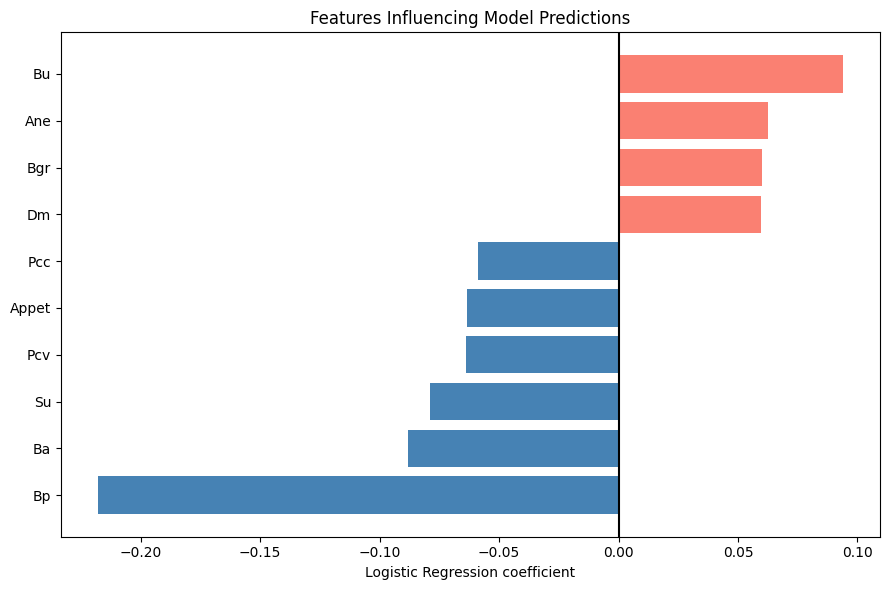

In [8]:
# Put the features in order for the chart
chart_data = top_features.sort_values("Coefficient")

colors = [
    "salmon" if value > 0 else "steelblue"
    for value in chart_data["Coefficient"]
]

plt.figure(figsize=(9, 6))
plt.barh(
    chart_data["Feature"],
    chart_data["Coefficient"],
    color=colors
)

plt.axvline(0, color="black")
plt.xlabel("Logistic Regression coefficient")
plt.title("Features Influencing Model Predictions")
plt.tight_layout()
plt.show()

In [9]:
from google.colab import files

# Save the cross-validation scores
results.to_csv("BD_KDD_logistic_results.csv", index=False)

# Download the results to your computer
files.download("BD_KDD_logistic_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
results.round(3)

,Metric,Mean,Standard deviation
0,accuracy,0.490,0.047
1,precision,0.502,0.041
2,recall,0.553,0.049
3,f1,0.526,0.045
4,roc_auc,0.474,0.030


In [11]:
# Look for relationships between measurements and diagnosis
training_data = X_train.copy()
training_data["Class"] = y_train

correlations = training_data.corr()["Class"].drop("Class")

correlations.abs().sort_values(ascending=False).head(10)

,Class
Bp,0.105695
Su,0.043237
Ba,0.041925
Bu,0.040507
Ane,0.039586
Rbcc,0.032541
Pcv,0.031427
Sc,0.031255
Appet,0.028376
Bgr,0.027494


In [12]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")

dummy_scores = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Simple baseline accuracy:",
      round(dummy_scores["test_score"].mean(), 3))

print("Logistic Regression accuracy:",
      round(scores["test_accuracy"].mean(), 3))

Simple baseline accuracy: 0.513
Logistic Regression accuracy: 0.49


In [13]:
print("Accuracy for each fold:")
print(scores["test_accuracy"].round(3))

Accuracy for each fold:
[0.437 0.475 0.494 0.468 0.576]
